In [1]:
import numpy as np
import pandas as pd
import pgmpy as pg
import pickle
from pgmpy.models import DiscreteBayesianNetwork
import networkx as nx
import matplotlib.pyplot as plt
from causes import *
from pgmpy.inference import VariableElimination
import itertools
import warnings


pd.set_option('display.max_rows', None)       
pd.set_option('display.max_columns', None)     
pd.set_option('display.width', None)           
pd.set_option('display.max_colwidth', None)


In [2]:
with open("pickles/IIT_estimator.pkl", "rb") as f:
    iit_estimator = pickle.load(f)

In [3]:
iit_network = DiscreteBayesianNetwork(mental_health_causes_taste)
for cpd in iit_estimator.get_parameters():
    iit_network.add_cpds(cpd)
    

First, we want show the Markov blanket for some variables of interest (Fav genre, Anxiety, Depression, Insomnia, and OCD), which is composed of the parents, children, and children's parents, and provides insight into the complete information required to infer the target node: nodes are independent of nodes that are not within their Markov blanket. In this case, due to modelling assumptions resulting in a densely connected network, the Markov blanket for the four conditions is the entire network, but we can see that Fav genre is independent of While Working, Exploratory, and Hours of Day.

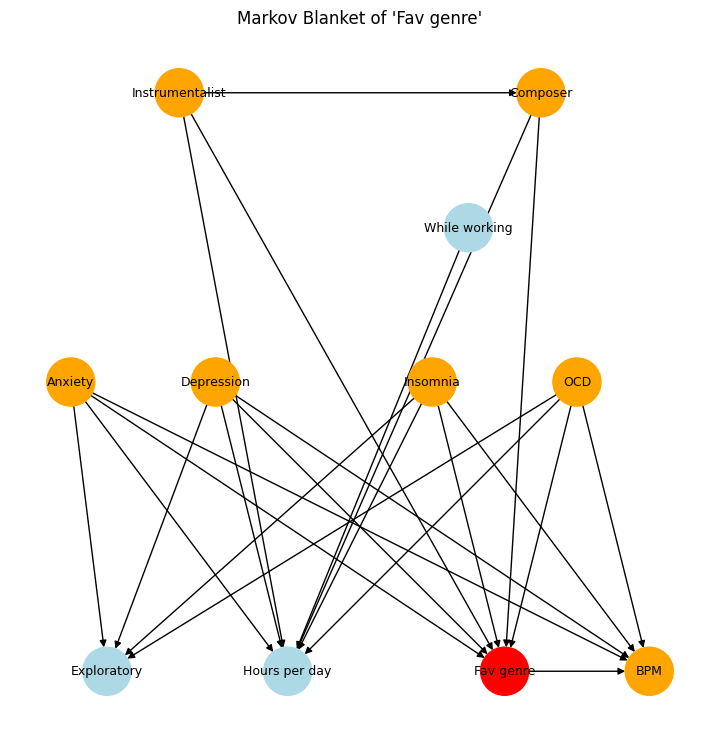

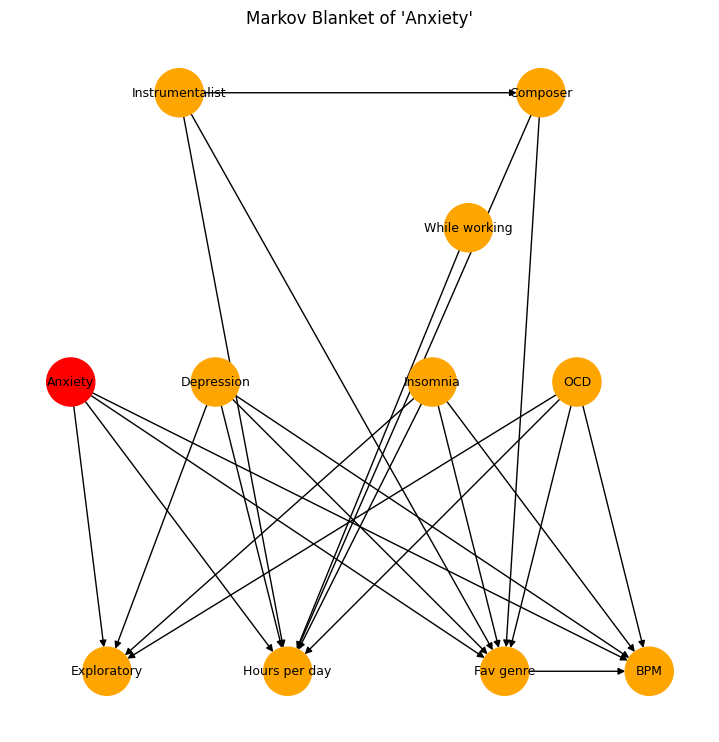

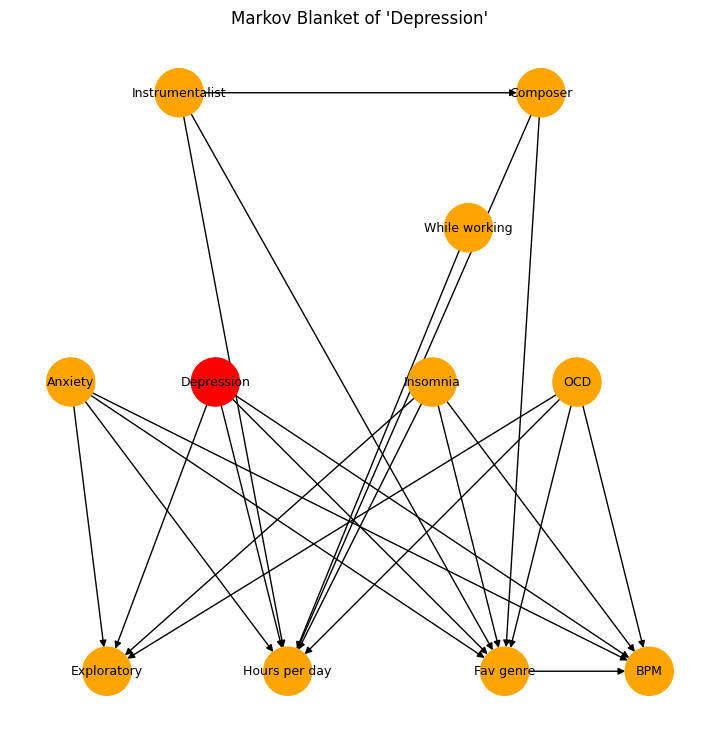

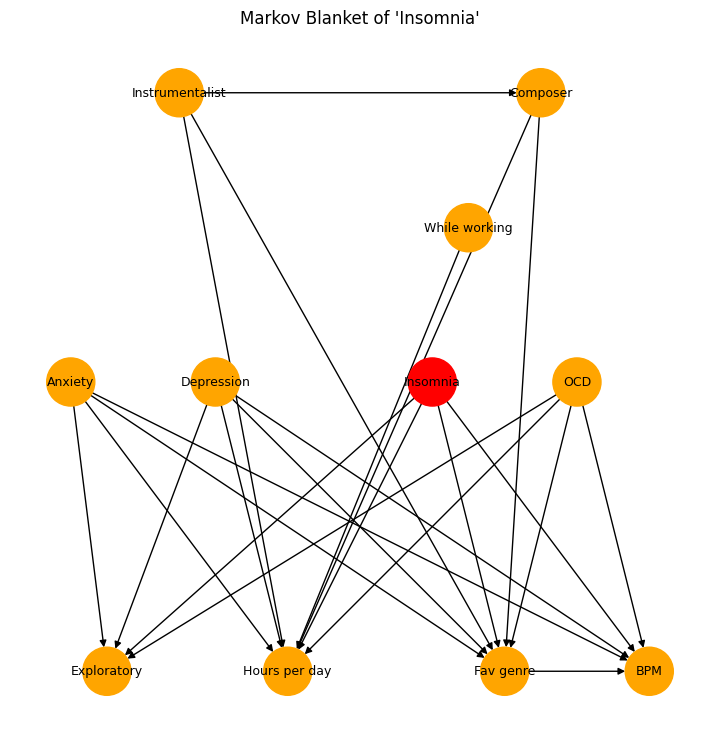

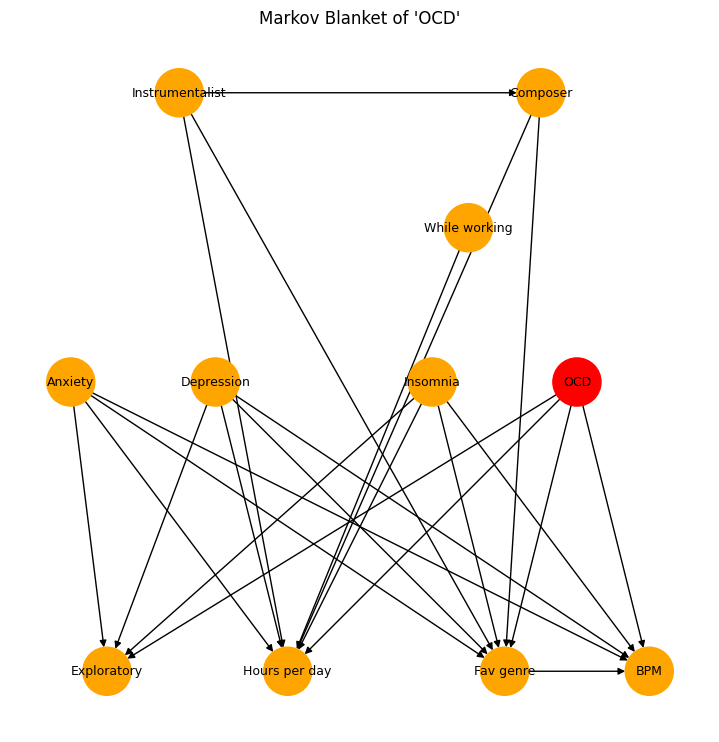

In [4]:
pos = {'Age': [0.5, -0.5],
        'Instrumentalist': [0.25, -1],
        'Composer': [0.75, -1],
        'While working': [0.65, - 1.35],
        'Anxiety': [0.1, -1.75],
        'Depression': [0.3, -1.75],
        'Insomnia': [0.6, -1.75],
        'OCD': [0.8, -1.75],
        'Exploratory': [0.15, -2.5],
        'Hours per day': [0.4, -2.5],
        'Fav genre': [0.7, -2.5],
        'BPM': [0.9, -2.5]
}

def plot_markov_blanket(model, target,
                        target_color="red",
                        blanket_color="orange",
                        other_color="lightblue"):
    
    mb = set(model.get_markov_blanket(target))

    G = nx.DiGraph()
    G.add_nodes_from(model.nodes())
    G.add_edges_from(model.edges())

    node_colors = []
    for node in G.nodes():
        if node == target:
            node_colors.append(target_color)
        elif node in mb:
            node_colors.append(blanket_color)
        else:
            node_colors.append(other_color)

    plt.figure(figsize=(7, 7))

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_color=node_colors,
        node_size=1200,
        font_size=9,
        arrows=True
    )

    plt.title(f"Markov Blanket of '{target}'")
    plt.show()


variables = ["Fav genre", "Anxiety", "Depression", "Insomnia", "OCD"]

# ---- Plot for each ----
for var in variables:
    plot_markov_blanket(iit_network, var)

An **active trail** in a Bayesian network is a path through the graph along which probabilistic influence can flow. Intuitively, if there is an active trail between nodes A and B, then observing A can change the probability distribution of B.
When no such influence is possible, the nodes are said to be **d-separated.**

For the same set of variables, we also report the ratio of active trails when one variable is observed and compare it to the ratio when all variables are unobserved. The observed ratio is **62%, compared to 54%** when unobserved, indicating that conditioning on these variables increases the number of active trails and thus enhances probabilistic influence across the network.

In [5]:
def find_active_trails(model, variables=None):
    
    all_nodes = list(model.nodes())
    results = []

    total_pairs = 0
    total_active = 0

    if not variables:
        variables = [None]

    for cond in variables:
        if cond is None:
            others = all_nodes
        else:
            others = [n for n in all_nodes if n != cond]

        for X, Y in itertools.combinations(others, 2):
            total_pairs += 1

            if cond is None:
                active = model.is_dconnected(X, Y)
            else:
                active = model.is_dconnected(X, Y, observed={cond})

            if active:
                total_active += 1
                results.append({
                    "Observed": cond,
                    "From": X,
                    "To": Y
                })

    ratio = total_active / total_pairs if total_pairs > 0 else 0
    print(f"Active trails: {total_active}/{total_pairs} ({ratio:.4f})")

    return pd.DataFrame(results)

df_active_trails_given_observed = find_active_trails(iit_network, variables)
df_active_trails_given_observed

Active trails: 141/225 (0.6267)


,Observed,From,To
0,Fav genre,Anxiety,BPM
1,Fav genre,Anxiety,Hours per day
2,Fav genre,Anxiety,Exploratory
3,Fav genre,Anxiety,Depression
4,Fav genre,Anxiety,Insomnia
5,Fav genre,Anxiety,OCD
6,Fav genre,Anxiety,Instrumentalist
7,Fav genre,Anxiety,Composer
8,Fav genre,BPM,Hours per day
9,Fav genre,BPM,Exploratory


In [6]:
df_active_trails_no_observed = find_active_trails(iit_network)
df_active_trails_no_observed

Active trails: 30/55 (0.5455)


,Observed,From,To
0,None,Anxiety,Fav genre
1,None,Anxiety,BPM
2,None,Anxiety,Hours per day
3,None,Anxiety,Exploratory
4,None,Fav genre,BPM
5,None,Fav genre,Hours per day
6,None,Fav genre,Exploratory
7,None,Fav genre,Depression
8,None,Fav genre,Insomnia
9,None,Fav genre,OCD


Finally, we turn our attention to a variety of queries to infer concerning several anecdotally interesting questions. We make a distinction between cases where some features take on an exact value (e.g. Anxiety = 3, Fav genre = Rock) vs. **cumulative** cases (e.g. Anxiety >= 2, Fav genre = [Rock, Metal, Hip hop]) in order to make a **more generalized inference** that is more limited in terms of user bias when completing the form the original dataset takes from.

First, we are interested in the probability of a favorite genre given a single one of the four internalizing conditions, P (Fav genre | {one of Anxiety, Depression, Insomnia, OCD}), in order to isolate what kind of effect each condition has individually on music taste.

Then, we move on to inferring **comorbidity**: mental health problems have a tendency of comorbidity (simultaneous occurrence, potentially due to latent factors), so we query Anxiety, Depression and Insomnia's distributions given one of the others and one of two different genres: Rock (as a upbeat, energetic genre that has sometimes culturally been seen as "problematic") and Jazz (as a generaly more relaxing, more ambiental genre).

We are then interested in BPM differences between Anxiety and Depression to reason about whether anxious/depressed individuals use music with different tempos as a coping mechanism. The same two conditions are used to reason about listening habits while working.

Finally, we answer three more questions: 1. Do people suffering from insomnia tend to be exploratory listeners (potentially late at night)? 2. Does having OCD come with a high probability on fixation on music and long listening hours daily? 3. How does the distribution of favorite genres look like in people who reported **all four** conditions?


In [7]:
genre_given_single_condition_queries = {
    # Fav genre conditioned on single mental health condition
    "Fav genre | Anxiety = 3": {
        "query_var": "Fav genre",
        "evidence": {"Anxiety": 3}
    },
    "Fav genre | Depression = 3": {
        "query_var": "Fav genre",
        "evidence": {"Depression": 3}
    },
    "Fav genre | Insomnia = 3": {
        "query_var": "Fav genre",
        "evidence": {"Insomnia": 3}
    },
    "Fav genre | OCD = 1": {
        "query_var": "Fav genre",
        "evidence": {"OCD": 1}
    }

}

comorbidities_queries_anxiety = {
    "Anxiety | Fav genre = Rock, Depression = 3": {
        "query_var": "Anxiety",
        "evidence": {"Fav genre": "Rock", "Depression": 3}
    },
    "Anxiety | Fav genre = Jazz, Depression = 3": {
        "query_var": "Anxiety",
        "evidence": {"Fav genre": "Jazz", "Depression": 3}
    }
}

comorbidities_queries_depression = {
    "Depression | Fav genre = Rock, Anxiety = 3": {
        "query_var": "Depression",
        "evidence": {"Fav genre": "Rock", "Anxiety": 3}
    },
    "Depression | Fav genre = Jazz, Anxiety = 3": {
        "query_var": "Depression",
        "evidence": {"Fav genre": "Jazz", "Anxiety": 3}
    }
}

comorbidities_queries_insomnia = {
     "Insomnia | Fav genre = Rock, Depression = 3": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": "Rock", "Depression": 3}
    },
    "Insomnia | Fav genre = Rock, Anxiety = 3": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": "Rock", "Anxiety": 3}
    },
    "Insomnia | Fav genre = Jazz, Depression = 3": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": "Jazz", "Depression": 3}
    },
    "Insomnia | Fav genre = Jazz, Anxiety = 3": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": "Jazz", "Anxiety": 3}
    }
}

bpm_queries = {
    # Do anxious people listen to faster music?
    "BPM | Anxiety": {
        "query_var": "BPM",
        "evidence": {"Anxiety": 3}
    },
    # Do depressed people listen to slower music?
    "BPM | Depression": {
        "query_var": "BPM",
        "evidence": {"Depression": 3}
    }
}

while_working_queries = {
    # Do people use music while working to cope with mental health conditions?
    "While working | Anxiety": {
        "query_var": "While working",
        "evidence": {"Anxiety": 3}
    },

    "While working | Depression": {
        "query_var": "While working",
        "evidence": {"Depression": 3}
        }
}

insomnia_exploratory = {
    # Do people with insomnia listen to a variety of music (late at night)?
    "Insomnia | Exploratory": {
        "query_var": "Insomnia",
        "evidence": {"Exploratory": "Yes"}
    }
}

ocd_hours_per_day = {
    # Does OCD affect listening duration (through a fixation on music?
    "OCD | Hours per day": {
        "query_var": "OCD",
        "evidence": {"Hours per day": 3}
    }
}

all_comorbidities = {
    # How does comorbidity of all conditions affect the favorite genre distribution?
    "Fav genre | Anxiety, Depression, Insomnia, OCD": {
        "query_var": "Fav genre",
        "evidence": {"Anxiety": 3, "Depression": 3, "Insomnia": 3, "OCD": 1}
    }

}

For inference, we use the simple and well-known **Variable Elimination** algorithm. It answers probability queries by removing irrelevant variables one at a time.

Variablr Elimination works in the following way:

- Collect the factors (the CPTs) and apply any evidence;

- For each variable that is not part of the query:

    - Multiply all factors that contain that variable;

    - Sum it out (marginalize it);

    - Put the resulting smaller factor back;

- When only the query variables remain, multiply the remaining factors and normalize.

In [8]:
infer = VariableElimination(iit_network)

In [9]:
def inference_summary(infer, query_dict):
    rows = []

    for name, q in query_dict.items():
        var = q["query_var"]
        evidence = q.get("evidence", {})
        evidence_lists = {}

        for k, v in evidence.items():
            if isinstance(v, list):
                evidence_lists[k] = v
            else:
                evidence_lists[k] = [v]

        all_combinations = [{}]
        for k, values in evidence_lists.items():
            new_combinations = []
            for val in values:
                for combo in all_combinations:
                    new_combo = combo.copy()
                    new_combo[k] = val
                    new_combinations.append(new_combo)
            all_combinations = new_combinations

        aggregated_probs = None
        for combo in all_combinations:
            factor = infer.query(variables=[var], evidence=combo)
            factor = factor if isinstance(factor, type(factor)) else factor[var]
            probs = factor.values
            if aggregated_probs is None:
                aggregated_probs = probs.copy()
            else:
                aggregated_probs += probs

        aggregated_probs /= aggregated_probs.sum()

        values_names = factor.state_names[var]
        row = {f"{var}={v}": p for v, p in zip(values_names, aggregated_probs)}

        if evidence:
            evidence_str = ", ".join(
                f"{k}={v}" if not isinstance(v, list) else f"{k} in {v}"
                for k, v in evidence.items()
            )
        else:
            evidence_str = ""
        row["Evidence"] = evidence_str

        max_idx = aggregated_probs.argmax()
        row["Highest Probability"] = f"{var}={values_names[max_idx]} ({aggregated_probs[max_idx]:.4f})"

        rows.append(row)

    df_summary = pd.DataFrame(rows)
    value_cols = [c for c in df_summary.columns if c not in ["Evidence", "Highest Probability"]]
    df_summary = df_summary[["Evidence"] + value_cols + ["Highest Probability"]]

    pd.set_option('display.max_rows', None)
    pd.set_option('display.float_format', '{:.4f}'.format)

    return df_summary


Rock is the most popular genre in our dataset, so it's unsurprising to see it as the most popular genre given each mental health condition individually. However, its prevalence as a favorite genre among anxious or depressed individuals is notably higher. Surprisingly, though, in all cases, **its prevalence as a favorite genre is lower** than in the whole dataset. The distributions for most other genres are similar, but one interesting insight is the **significantly higher probability of Fav genre = Metal given Insomnia (19.5%) vs. the other conditions, which range between 6.7 and 8.8%.**

In [10]:
inference_summary(infer, genre_given_single_condition_queries)

,Evidence,Fav genre=Classical,Fav genre=Country,Fav genre=EDM,Fav genre=Folk,Fav genre=Gospel,Fav genre=Hip hop,Fav genre=Jazz,Fav genre=K pop,Fav genre=Latin,Fav genre=Lofi,Fav genre=Metal,Fav genre=Pop,Fav genre=R&B,Fav genre=Rap,Fav genre=Rock,Fav genre=Video game music,Highest Probability
0,Anxiety=3,0.0434,0.0557,0.0427,0.1255,0.0134,0.0498,0.0254,0.0553,0.0170,0.0164,0.0643,0.1161,0.0350,0.0353,0.2489,0.0559,Fav genre=Rock (0.2489)
1,Depression=3,0.0512,0.0362,0.0460,0.0293,0.0190,0.0641,0.0392,0.0489,0.0190,0.0680,0.0880,0.1021,0.0314,0.0481,0.2698,0.0398,Fav genre=Rock (0.2698)
2,Insomnia=3,0.0681,0.0336,0.0481,0.0407,0.0304,0.0444,0.0365,0.0233,0.0248,0.0572,0.1975,0.1005,0.0511,0.0233,0.1579,0.0629,Fav genre=Metal (0.1975)
3,OCD=1,0.0380,0.0589,0.0586,0.0437,0.0241,0.0467,0.0392,0.0487,0.0248,0.0311,0.0808,0.1587,0.0520,0.0504,0.1960,0.0483,Fav genre=Rock (0.1960)


Delving into comorbidities, we observe that **in depressed individuals, Anxiety is quite comorbid**, with the distribution being meaningfully more skewed towards high anxiety when the favorite genre is Rock. The inverse also holds true, but to a lesser extent: the distributions imply that depression is less likely in anxious individuals than vice versa. In this case, Rock is again the genre associated with higher Depression.

In regards to Insomnia, we can observe a greater influence of Anxiety over it compared to Depression, **possibly suggesting that anxious thoughts may keep people up late**. We cannot conclusively infer which of the genre preferences co-occurs with worse insomnia, but the case Fav genre = Jazz | Depression = 3 is notably distributed towards the extremes: very likely to be either no insomnia or very high insomnia.

In [11]:
inference_summary(infer, comorbidities_queries_anxiety)

,Evidence,Anxiety=0,Anxiety=1,Anxiety=2,Anxiety=3,Highest Probability
0,"Fav genre=Rock, Depression=3",0.0282,0.1618,0.4728,0.3371,Anxiety=2 (0.4728)
1,"Fav genre=Jazz, Depression=3",0.1020,0.2192,0.4668,0.2120,Anxiety=2 (0.4668)


In [12]:
inference_summary(infer, comorbidities_queries_depression)

,Evidence,Depression=0,Depression=1,Depression=2,Depression=3,Highest Probability
0,"Fav genre=Rock, Anxiety=3",0.0492,0.3553,0.3507,0.2449,Depression=1 (0.3553)
1,"Fav genre=Jazz, Anxiety=3",0.2022,0.2819,0.2967,0.2193,Depression=2 (0.2967)


In [13]:
inference_summary(infer, comorbidities_queries_insomnia)

,Evidence,Insomnia=0,Insomnia=1,Insomnia=2,Insomnia=3,Highest Probability
0,"Fav genre=Rock, Depression=3",0.3344,0.3985,0.1986,0.0685,Insomnia=1 (0.3985)
1,"Fav genre=Rock, Anxiety=3",0.2448,0.2963,0.3195,0.1394,Insomnia=2 (0.3195)
2,"Fav genre=Jazz, Depression=3",0.4365,0.1357,0.2003,0.2275,Insomnia=0 (0.4365)
3,"Fav genre=Jazz, Anxiety=3",0.1633,0.4522,0.2393,0.1451,Insomnia=1 (0.4522)


The inference suggests that people generally listen to similar music tempos (in the typical range) for both the Anxiety and Depression cases, and this distribution is similar to the general BPM distribution in the dataset, but there is a very slight skew towards faster BPM with high depression, which does not follow initial intuition but may be explained by faster music providing a "kick" that serves as a coping mechanism.

In [14]:
inference_summary(infer, bpm_queries)

,Evidence,BPM=0,BPM=1,BPM=2,BPM=3,Highest Probability
0,Anxiety=3,0.0673,0.4554,0.4260,0.0513,BPM=1 (0.4554)
1,Depression=3,0.0834,0.4092,0.4352,0.0723,BPM=2 (0.4352)


The next three queries don't lead to insightful answers and are inconclusive at best. In particular, the probability distribution over While working given Anxiety or Depression is exactly the same. Exploratory and hours-per-day tendencies given the conditions share a very similar distribution to the unconditioned distributions.

In [15]:
inference_summary(infer, while_working_queries)

,Evidence,While working=No,While working=Yes,Highest Probability
0,Anxiety=3,0.2053,0.7947,While working=Yes (0.7947)
1,Depression=3,0.2053,0.7947,While working=Yes (0.7947)


In [16]:
inference_summary(infer, insomnia_exploratory)

,Evidence,Insomnia=0,Insomnia=1,Insomnia=2,Insomnia=3,Highest Probability
0,Exploratory=Yes,0.3019,0.3011,0.2509,0.1461,Insomnia=0 (0.3019)


In [17]:
inference_summary(infer, ocd_hours_per_day)

,Evidence,OCD=0,OCD=1,Highest Probability
0,Hours per day=3,0.6710,0.3290,OCD=0 (0.6710)


The results of the following query about the combination of all 4 comorbidities cannot be taken as conclusive because the low sample size impacts the ability to generalize and results in many genres having the same probabilities as each other. Still, with our limited data, the winner is Metal.

In [18]:
inference_summary(infer, all_comorbidities)

,Evidence,Fav genre=Classical,Fav genre=Country,Fav genre=EDM,Fav genre=Folk,Fav genre=Gospel,Fav genre=Hip hop,Fav genre=Jazz,Fav genre=K pop,Fav genre=Latin,Fav genre=Lofi,Fav genre=Metal,Fav genre=Pop,Fav genre=R&B,Fav genre=Rap,Fav genre=Rock,Fav genre=Video game music,Highest Probability
0,"Anxiety=3, Depression=3, Insomnia=3, OCD=1",0.0149,0.1197,0.1197,0.1197,0.0149,0.0149,0.0592,0.0149,0.0149,0.0149,0.1640,0.0592,0.1197,0.0149,0.0149,0.1197,Fav genre=Metal (0.1640)


As mentioned above, we also consider queries with ranges instead of precise values, both for the conditions Anxiety, Insomnia and Depression, and for the favorite genres, where we group Rock, Metal and Hip hop (three genres often stereotyped to induce mental health issues or deviant behavior) as one case, and Jazz, Lo-fi and Gospel (genres stereotypes as "calmer") as another.

In [19]:
genre_given_single_condition_queries_range = {
    # Fav genre conditioned on single mental health condition
    "Fav genre | Anxiety >= 2": {
        "query_var": "Fav genre",
        "evidence": {"Anxiety": [2,3]}
    },
    "Fav genre | Depression  >= 2": {
        "query_var": "Fav genre",
        "evidence": {"Depression": [2,3]}
    },
    "Fav genre | Insomnia >= 2": {
        "query_var": "Fav genre",
        "evidence": {"Insomnia": [2,3]}
    }
}

comorbidities_queries_anxiety_range = {
    "Anxiety | Fav genre = Rock, metal or hip-hop, Depression >= 2": {
        "query_var": "Anxiety",
        "evidence": {"Fav genre": ["Rock", "Metal", "Hip hop"], "Depression": [2,3]}
    },
    "Anxiety | Fav genre = Jazz, gospel or lo-fi, Depression >= 2": {
        "query_var": "Anxiety",
        "evidence": {"Fav genre": ["Jazz", "Gospel", "Lofi"], "Depression": [2, 3]}
    }
}

comorbidities_queries_depression_range = {
    "Depression | Fav genre = Rock, metal or hip-hop, Anxiety >= 2": {
        "query_var": "Depression",
        "evidence": {"Fav genre": ["Rock", "Metal", "Hip hop"], "Anxiety": [2,3]}
    },
    "Depression | Fav genre = Jazz, gospel or lo-fi, Anxiety >= 2": {
        "query_var": "Depression",
        "evidence": {"Fav genre": ["Jazz", "Gospel", "Lofi"], "Anxiety": [2,3]}
    }
}

comorbidities_queries_insomnia_range = {
     "Insomnia | Fav genre = Rock, metal or hip-hop, Depression >= 2": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": ["Rock", "Metal", "Hip hop"], "Depression": [2, 3]}
    },
    "Insomnia | Fav genre = Rock, metal or hip-hop, Anxiety >= 2": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": ["Rock", "Metal", "Hip hop"], "Anxiety": [2,3]}
    },
    "Insomnia | Fav genre = Jazz, gospel or lo-fi, Depression >= 2": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": ["Jazz", "Gospel", "Lofi"], "Depression": [2,3]}
    },
    "Insomnia | Fav genre = Jazz, gospel or lo-fi, Anxiety >= 2": {
        "query_var": "Insomnia",
        "evidence": {"Fav genre": ["Jazz", "Gospel", "Lofi"], "Anxiety": [2,3]}
    }
}

bpm_queries_range = {
    # Do anxious people listen to faster music?
    "BPM | Anxiety >= 2": {
        "query_var": "BPM",
        "evidence": {"Anxiety": [2,3]}
    },
    # Do depressed people listen to slower music?
    "BPM | Depression >= 2": {
        "query_var": "BPM",
        "evidence": {"Depression": [2,3]}
    }
}

while_working_queries_range = {
    # Do people use music while working to cope with mental health conditions?
    "While working | Anxiety >= 2": {
        "query_var": "While working",
        "evidence": {"Anxiety": [2,3]}
    },

    "While working | Depression >= 2": {
        "query_var": "While working",
        "evidence": {"Depression": [2,3]}
        }
}

ocd_hours_per_day_range = {
    # Does OCD affect listening duration (through a fixation on music?
    "OCD | Hours per day >= 2": {
        "query_var": "OCD",
        "evidence": {"Hours per day": [2,3]}
    }
}

all_comorbidities_range = {
    # How does comorbidity of all conditions affect the favorite genre distribution?
    "Fav genre | Anxiety >= 2, Depression >= 2, Insomnia >= 2, OCD": {
        "query_var": "Fav genre",
        "evidence": {"Anxiety": [2,3], "Depression": [2,3], "Insomnia": [2,3], "OCD": 1}
    }

}

As expected, Rock is the most common favorite genre in all three cases, but introducing ranges has smoothed out the difference considerably, and this holds for all the distributions in general.

In [20]:
inference_summary(infer, genre_given_single_condition_queries_range)

,Evidence,Fav genre=Classical,Fav genre=Country,Fav genre=EDM,Fav genre=Folk,Fav genre=Gospel,Fav genre=Hip hop,Fav genre=Jazz,Fav genre=K pop,Fav genre=Latin,Fav genre=Lofi,Fav genre=Metal,Fav genre=Pop,Fav genre=R&B,Fav genre=Rap,Fav genre=Rock,Fav genre=Video game music,Highest Probability
0,"Anxiety in [2, 3]",0.0431,0.0457,0.0428,0.0770,0.0139,0.0538,0.0298,0.0543,0.0142,0.0203,0.0938,0.1563,0.0370,0.0285,0.2313,0.0582,Fav genre=Rock (0.2313)
1,"Depression in [2, 3]",0.0608,0.0351,0.0451,0.0502,0.0162,0.0676,0.0306,0.0426,0.0180,0.0432,0.1021,0.1263,0.0393,0.0353,0.2357,0.0518,Fav genre=Rock (0.2357)
2,"Insomnia in [2, 3]",0.0674,0.0329,0.0546,0.0599,0.0233,0.0379,0.0314,0.0470,0.0204,0.0513,0.1453,0.1051,0.0461,0.0231,0.1959,0.0585,Fav genre=Rock (0.1959)


Taking into account moderate or high depression as well as a range of different genres in the two groups amplified the difference in distribution for anxiety. **Jazz, gospel and lo-fi are associated with significantly lower anxiety given moderate or high depression. The same holds in reverse,** with this group of genres being associated with significantly lower depression given moderate-high anxiety.

Interestingly, this group of genres is **also associated with significantly higher insomnia**, which could be explained by people listening to them before bed in an attempt to unwind. In these conditions, insomnia again seems more comorbid with anxiety, like before.

In [21]:
inference_summary(infer, comorbidities_queries_anxiety_range)

,Evidence,Anxiety=0,Anxiety=1,Anxiety=2,Anxiety=3,Highest Probability
0,"Fav genre in ['Rock', 'Metal', 'Hip hop'], Depression in [2, 3]",0.0611,0.1980,0.4048,0.3361,Anxiety=2 (0.4048)
1,"Fav genre in ['Jazz', 'Gospel', 'Lofi'], Depression in [2, 3]",0.1796,0.3398,0.2935,0.1872,Anxiety=1 (0.3398)


In [22]:
inference_summary(infer, comorbidities_queries_depression_range)

,Evidence,Depression=0,Depression=1,Depression=2,Depression=3,Highest Probability
0,"Fav genre in ['Rock', 'Metal', 'Hip hop'], Anxiety in [2, 3]",0.0910,0.2358,0.4012,0.2721,Depression=2 (0.4012)
1,"Fav genre in ['Jazz', 'Gospel', 'Lofi'], Anxiety in [2, 3]",0.2927,0.2413,0.2092,0.2568,Depression=0 (0.2927)


In [23]:
inference_summary(infer, comorbidities_queries_insomnia_range)   

,Evidence,Insomnia=0,Insomnia=1,Insomnia=2,Insomnia=3,Highest Probability
0,"Fav genre in ['Rock', 'Metal', 'Hip hop'], Depression in [2, 3]",0.3062,0.3616,0.1890,0.1432,Insomnia=1 (0.3616)
1,"Fav genre in ['Rock', 'Metal', 'Hip hop'], Anxiety in [2, 3]",0.2713,0.3245,0.2280,0.1761,Insomnia=1 (0.3245)
2,"Fav genre in ['Jazz', 'Gospel', 'Lofi'], Depression in [2, 3]",0.2907,0.2601,0.2336,0.2157,Insomnia=0 (0.2907)
3,"Fav genre in ['Jazz', 'Gospel', 'Lofi'], Anxiety in [2, 3]",0.2069,0.2776,0.2567,0.2589,Insomnia=1 (0.2776)


There is no meaningful change in the next three queries caused by introducing ranges. There still don't seem to be any relationships.

In [24]:
inference_summary(infer, bpm_queries_range)

,Evidence,BPM=0,BPM=1,BPM=2,BPM=3,Highest Probability
0,"Anxiety in [2, 3]",0.0618,0.4435,0.4473,0.0474,BPM=2 (0.4473)
1,"Depression in [2, 3]",0.0708,0.4308,0.4356,0.0628,BPM=2 (0.4356)


In [25]:
inference_summary(infer, while_working_queries_range)

,Evidence,While working=No,While working=Yes,Highest Probability
0,"Anxiety in [2, 3]",0.2053,0.7947,While working=Yes (0.7947)
1,"Depression in [2, 3]",0.2053,0.7947,While working=Yes (0.7947)


In [26]:
inference_summary(infer, ocd_hours_per_day_range)

,Evidence,OCD=0,OCD=1,Highest Probability
0,"Hours per day in [2, 3]",0.6849,0.3151,OCD=0 (0.6849)


Allowing for ranges for the conditions allows for a **significantly expanded sample size, which lends us the ability to reason** upon this query. The distribution is even more skewed towards Metal being the most probable favorite genre, an interesting result given the significant difference (21.6% vs 16.6%) between it and Rock, which is the most probable favorite genre overall without conditions.

In [27]:
inference_summary(infer, all_comorbidities_range)

,Evidence,Fav genre=Classical,Fav genre=Country,Fav genre=EDM,Fav genre=Folk,Fav genre=Gospel,Fav genre=Hip hop,Fav genre=Jazz,Fav genre=K pop,Fav genre=Latin,Fav genre=Lofi,Fav genre=Metal,Fav genre=Pop,Fav genre=R&B,Fav genre=Rap,Fav genre=Rock,Fav genre=Video game music,Highest Probability
0,"Anxiety in [2, 3], Depression in [2, 3], Insomnia in [2, 3], OCD=1",0.0466,0.0488,0.0550,0.0757,0.0079,0.0389,0.0412,0.0554,0.0079,0.0479,0.2174,0.0990,0.0322,0.0233,0.1666,0.0363,Fav genre=Metal (0.2174)
